In [4]:
import sys
import os
sys.path.append("..")
from geomatry.opt_Energy_approximated.optimizer import MultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param
import torch
import copy

def onlyRsquare(k_perturbed, r0_perturbed, optimizer):
    ff.reset_parameters(k_perturbed, r0_perturbed)
    params_0 = ff.state_dict()
    print("params_optimized",optimizer.optimize(params_0))
    print("params_answer",k, r0)
    return copy.deepcopy(params_0)

import copy

systemN = 40
N = 20
N_pairs = 50
max_Za = 5
Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, r0_max=10, k_max=10)
ff = SpringFF(max_Za)
ff.reset_parameters(k, r0)

fixed_atom_indices = [0,1,2]
graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

# start implicit optimization
import copy
params_star = copy.deepcopy(ff.state_dict())
#params_star = copy.deepcopy(ff.state_dict())
#print("params_star", params_star)
optimizer = MultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss, 
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
k_perturbed = torch.abs(k.clone() + 3 * torch.randn_like(k))
r0_perturbed = torch.abs(r0.clone() + 3 * torch.randn_like(r0))

#k_perturbed = -k.clone()
#r0_perturbed = torch.clamp(r0.clone() + 0.1 * torch.randn_like(r0), min=0)

ff.reset_parameters(k_perturbed, r0_perturbed)
params_0 = copy.deepcopy(ff.state_dict())

print('start', params_0)
print('goal',params_star)

/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/demo/../geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)


start OrderedDict({'k': tensor([[ 5.1714,  7.6669,  8.1412,  7.2553,  2.4463,  0.6525],
        [ 7.6669,  5.0041,  2.1307,  3.0943,  3.4296,  7.1986],
        [ 8.1412,  2.1307,  4.2569,  4.5495,  5.2007,  3.2153],
        [ 7.2553,  3.0943,  4.5495,  8.3243,  5.6085,  0.5591],
        [ 2.4463,  3.4296,  5.2007,  5.6085,  8.4233,  8.5483],
        [ 0.6525,  7.1986,  3.2153,  0.5591,  8.5483, 13.0762]],
       dtype=torch.float64), 'r0': tensor([[ 4.5792,  3.7390,  3.4622,  3.1717,  4.8930,  0.9001],
        [ 3.7390,  2.3724,  2.4989,  0.6134,  2.8224,  1.9892],
        [ 3.4622,  2.4989,  5.3157,  4.7816,  5.9634,  5.1716],
        [ 3.1717,  0.6134,  4.7816,  0.4483,  8.1821,  5.4615],
        [ 4.8930,  2.8224,  5.9634,  8.1821, 13.5469,  4.0561],
        [ 0.9001,  1.9892,  5.1716,  5.4615,  4.0561,  4.6372]],
       dtype=torch.float64)})
goal OrderedDict({'k': tensor([[3.7160, 8.9273, 4.6517, 7.4304, 2.9089, 4.0014],
        [8.9273, 4.7883, 4.7139, 6.0324, 3.8531, 6.5009],
  

Ra_star_energy tensor(1610.3374, dtype=torch.float64, grad_fn=<DivBackward0>)


/var/folders/d9/j9pnzj2s30jf7r3wxfwp0yz80000gn/T/ipykernel_81475/1966093366.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Ra_temp[:,:]+=x[i]*n1
/var/folders/d9/j9pnzj2s30jf7r3wxfwp0yz80000gn/T/ipykernel_81475/1966093366.py:33: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Ra_temp[:,:]-=x[i]*n1


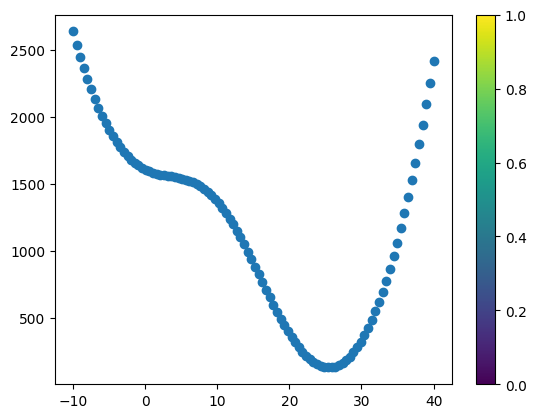

In [7]:
#Draw energy landscape near real optimal geometry
#In direction towards current local minimum
from torch import FloatTensor, IntTensor
from ase import Atoms
import numpy as np
import matplotlib.pyplot as plt

def get_ase_atoms(Ra: FloatTensor, Za: IntTensor) -> Atoms:
    return Atoms(
        positions=Ra.detach().cpu().numpy(),
        numbers=Za.detach().cpu().numpy()
    )

def getMaxDirection(optimizer, params_0, index):
    Ra_star_0=optimizer.fitting._get_Ra_star(params_0,optimizer.graph_builders[index],optimizer.Ra_stars[index],optimizer.Zas[index],optimizer.fixed_atom_indices)
    direction=(Ra_star_0-optimizer.Ra_stars[index]).detach().numpy()
    return direction/np.linalg.norm(direction)

def drawGraphs(optimizer,params, index):
    n1=getMaxDirection(optimizer,params, index)
    if (np.isnan(n1[0,0])):
        n1=np.zeros(n1.shape)
        n1[0,0]=1
    optimizer.ff.reset_parameters(params['k'],params['r0'])
    Ra_temp=copy.deepcopy(optimizer.Ra_stars[index])
    atoms=get_ase_atoms(Ra_temp, optimizer.Zas[index])
    x=np.linspace(-10,40,100)
    z1=copy.deepcopy(x)
    for i in range(100):
        Ra_temp[:,:]+=x[i]*n1
        E0=optimizer.ff.get_E(Ra_temp,optimizer.Zas[index],*optimizer.graph_builders[index](atoms))
        z1[i]=E0
        Ra_temp[:,:]-=x[i]*n1
    #z1[z1>30]=30
    print('Ra_star_energy',optimizer.ff.get_E(Ra_temp,optimizer.Zas[index],*optimizer.graph_builders[index](atoms)))
    plt.scatter(x,z1)
    plt.colorbar()
param={'k':k_perturbed, 'r0':r0_perturbed}
drawGraphs(optimizer,params_0,0)

params_0 OrderedDict({'k': tensor([[ 5.1714,  7.6669,  8.1412,  7.2553,  2.4463,  0.6525],
        [ 7.6669,  5.0041,  2.1307,  3.0943,  3.4296,  7.1986],
        [ 8.1412,  2.1307,  4.2569,  4.5495,  5.2007,  3.2153],
        [ 7.2553,  3.0943,  4.5495,  8.3243,  5.6085,  0.5591],
        [ 2.4463,  3.4296,  5.2007,  5.6085,  8.4233,  8.5483],
        [ 0.6525,  7.1986,  3.2153,  0.5591,  8.5483, 13.0762]],
       dtype=torch.float64), 'r0': tensor([[ 4.5792,  3.7390,  3.4622,  3.1717,  4.8930,  0.9001],
        [ 3.7390,  2.3724,  2.4989,  0.6134,  2.8224,  1.9892],
        [ 3.4622,  2.4989,  5.3157,  4.7816,  5.9634,  5.1716],
        [ 3.1717,  0.6134,  4.7816,  0.4483,  8.1821,  5.4615],
        [ 4.8930,  2.8224,  5.9634,  8.1821, 13.5469,  4.0561],
        [ 0.9001,  1.9892,  5.1716,  5.4615,  4.0561,  4.6372]],
       dtype=torch.float64)})


  0%|          | 0/60001 [00:00<?, ?it/s]

0 curvature 14.658249548331574 3564.4196774414227 distance 11.940318462690202 loss 9075.583286331537
trueloss 9075.583286331537
loss 9064.61696821779
tensor([-65.5495, -89.5675, -57.8122, -94.1423, -55.4858, -79.1315],
       dtype=torch.float64, grad_fn=<SubBackward0>)


/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/demo/../geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)


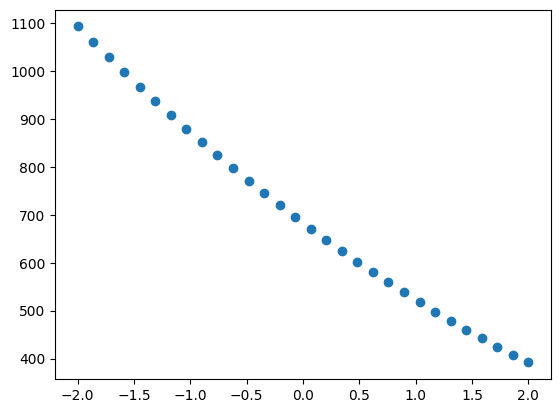

 33%|███▎      | 19996/60001 [02:03<03:54, 170.75it/s]

20000 curvature 1.9881664046703111 4.637144920513179 distance 1.0597142485406896 loss 23.566197974221197
trueloss 23.566197974221197
loss 16.432128599673128
tensor([-0.5437, -0.5475, -0.5531, -0.5545, -0.5176, -0.5547],
       dtype=torch.float64, grad_fn=<SubBackward0>)


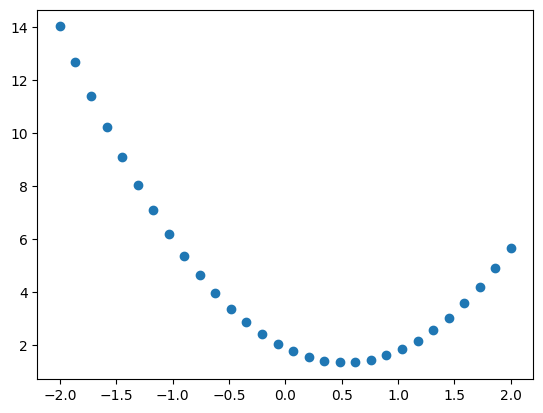

 67%|██████▋   | 39993/60001 [04:09<02:00, 165.61it/s]

40000 curvature 2.522729430521512 0.04784294523449581 distance 0.07121607361674973 loss 0.22610997873245947
trueloss 0.22610997873245947
loss 0.22610997873245947
tensor([0.3642, 0.4243, 0.5076, 0.2063, 0.4537, 0.6308], dtype=torch.float64,
       grad_fn=<SubBackward0>)


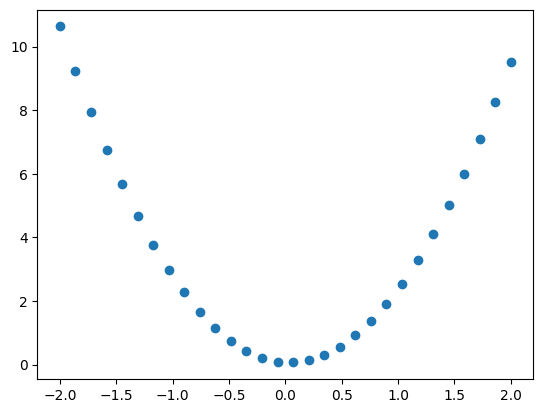

100%|█████████▉| 59999/60001 [06:10<00:00, 169.66it/s]

60000 curvature 0.9652217025568999 0.3643910766651011 distance 0.20406379021970295 loss 0.7715910740579166
trueloss 0.7715910740579166
loss 0.7715885403527858
tensor([0.1884, 0.0822, 0.0900, 0.1181, 0.1738, 0.1351], dtype=torch.float64,
       grad_fn=<SubBackward0>)


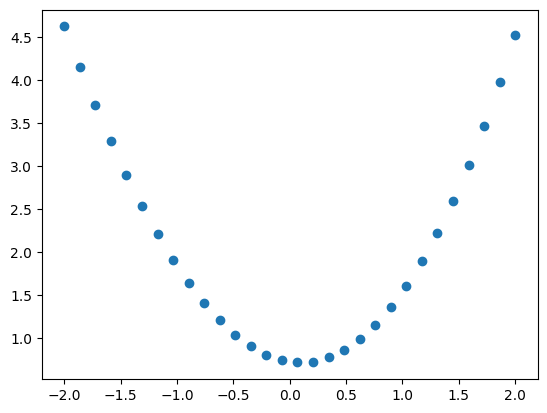

100%|██████████| 60001/60001 [06:10<00:00, 162.13it/s]


In [6]:
def energyAndRsquare(k_perturbed, r0_perturbed, optimizer):
    ff.reset_parameters(k_perturbed, r0_perturbed)
    params_0 = ff.state_dict()
    print("params_0", params_0)
    for i in range(1):
        params_0=optimizer.optimize(params_0, 60001, 20000, 0.1, 6, 2)
    return params_0
new_params_0=energyAndRsquare(k_perturbed, r0_perturbed, optimizer)


Ra_star_energy tensor(9.2568, dtype=torch.float64, grad_fn=<DivBackward0>)


/var/folders/d9/j9pnzj2s30jf7r3wxfwp0yz80000gn/T/ipykernel_81475/942741433.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Ra_temp[:,:]+=x[i]*n1
/var/folders/d9/j9pnzj2s30jf7r3wxfwp0yz80000gn/T/ipykernel_81475/942741433.py:33: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Ra_temp[:,:]-=x[i]*n1


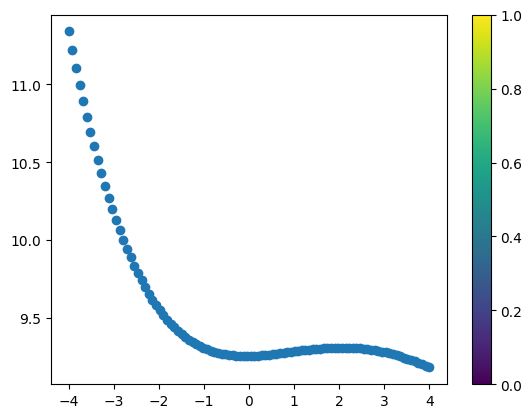

In [8]:
#Draw energy landscape near real optimal geometry
#In direction towards current local minimum
from torch import FloatTensor, IntTensor
from ase import Atoms
import numpy as np
import matplotlib.pyplot as plt

def get_ase_atoms(Ra: FloatTensor, Za: IntTensor) -> Atoms:
    return Atoms(
        positions=Ra.detach().cpu().numpy(),
        numbers=Za.detach().cpu().numpy()
    )

def getMaxDirection(optimizer, params_0, index):
    Ra_star_0=optimizer.fitting._get_Ra_star(params_0,optimizer.graph_builders[index],optimizer.Ra_stars[index],optimizer.Zas[index],optimizer.fixed_atom_indices)
    direction=(Ra_star_0-optimizer.Ra_stars[index]).detach().numpy()
    return direction/np.linalg.norm(direction)

def drawGraphs(optimizer,params, index):
    n1=getMaxDirection(optimizer,params, index)
    if (np.isnan(n1[0,0])):
        n1=np.zeros(n1.shape)
        n1[-1,0]=1
    optimizer.ff.reset_parameters(params['k'],params['r0'])
    Ra_temp=copy.deepcopy(optimizer.Ra_stars[index])
    atoms=get_ase_atoms(Ra_temp, optimizer.Zas[index])
    x=np.linspace(-4,4,100)
    z1=copy.deepcopy(x)
    for i in range(100):
        Ra_temp[:,:]+=x[i]*n1
        E0=optimizer.ff.get_E(Ra_temp,optimizer.Zas[index],*optimizer.graph_builders[index](atoms))
        z1[i]=E0
        Ra_temp[:,:]-=x[i]*n1
    #z1[z1>30]=30
    print('Ra_star_energy', optimizer.ff.get_E(Ra_temp,optimizer.Zas[index],*optimizer.graph_builders[index](atoms)))
    plt.scatter(x,z1)
    plt.colorbar()
param={'k':k_perturbed, 'r0':r0_perturbed}
drawGraphs(optimizer,new_params_0,0)

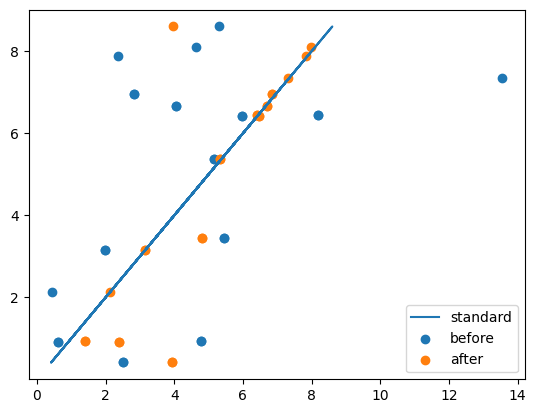

In [9]:
#Compare
import matplotlib.pyplot as plt

plt.plot(params_star['r0'][1:,1:].reshape(-1),params_star['r0'][1:,1:].reshape(-1),label='standard')
plt.scatter(params_0['r0'][1:,1:].reshape(-1),params_star['r0'][1:,1:].reshape(-1),label='before')
plt.scatter(new_params_0['r0'][1:,1:].reshape(-1),params_star['r0'][1:,1:].reshape(-1),label='after')
plt.legend()
plt.show()

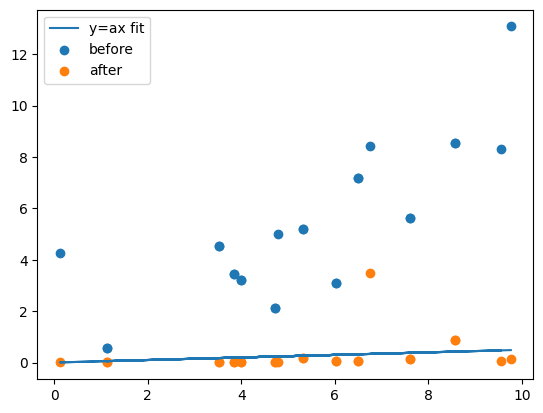

In [10]:
#Compare
import matplotlib.pyplot as plt

new_params_0['k']=(new_params_0['k']+new_params_0['k'].T)/2
params_star['k']=(params_star['k']+params_star['k'].T)/2
params_0['k']=(params_0['k']+params_0['k'].T)/2

a=torch.sum(new_params_0['k'][1:,1:].reshape(-1))/torch.sum(params_star['k'][1:,1:].reshape(-1))
plt.plot(params_star['k'][1:,1:].reshape(-1),a*params_star['k'][1:,1:].reshape(-1),label='y=ax fit')
plt.scatter(params_star['k'][1:,1:].reshape(-1),params_0['k'][1:,1:].reshape(-1),label='before')
plt.scatter(params_star['k'][1:,1:].reshape(-1),new_params_0['k'][1:,1:].reshape(-1),label='after')
plt.legend()
plt.show()